# ML Lab: Optimal Sparse Decision Trees (OSDT) 

**Paper:** Hu, Rudin, Seltzer — *Optimal Sparse Decision Trees*, NeurIPS 2019.

**Objective being minimised** (paper Eq. 4):

$$R(d) = \underbrace{\frac{1}{N}\sum_n \mathbb{1}[\hat y_n \neq y_n]}_{\text{misclassification}} \;+\; \lambda\, H_d$$

where $H_d$ = number of leaves and $\lambda$ is the price paid per leaf. Bigger $\lambda$ → sparser trees.

## 0. Setup

In [1]:
import time
import heapq
import itertools
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn is used ONLY for the CART baseline in the experiments.
from sklearn.tree import DecisionTreeClassifier


# popcount = number of 1-bits in a Python int
def popcount(x):
    return bin(x).count("1")


def to_bitvec(bool_arr):
    #Pack a boolean NumPy array into ONE Python integer (bit i  <->  sample i)
    packed = np.packbits(np.asarray(bool_arr, dtype=np.uint8))
    return int.from_bytes(packed.tobytes(), "big")


# quick demo of the bit-vector idea
a = to_bitvec(np.array([1, 1, 0, 1, 0, 0, 1, 0], dtype=bool))
b = to_bitvec(np.array([1, 0, 0, 1, 1, 0, 1, 1], dtype=bool))
print(f"a = {a}, b = {b}")
print("|A|=", popcount(a), " |B|=", popcount(b), " |A∩B|=", popcount(a & b))


a = 210, b = 155
|A|= 4  |B|= 5  |A∩B|= 3


## 1. The OSDT algorithm

### 1.1 Representation
A tree is stored **as a collection of leaves** (paper §3). Each leaf is a conjunction of
`(feature, value)` clauses plus a bit-vector of the training samples it captures.
Leaves are split into
* `fixed` leaves (the paper's $d_{un}$): will never be split again in this branch of the search,
* `splittable` leaves (the paper's $d_{split}$): may still be split.

To split a splittable leaf `S[j]`, all splittable leaves *before* it become fixed
(this removes the permutation symmetry of Corollary E.1: every tree is generated through a
single canonical order of splits). The two new children may each be fixed or splittable.

### 1.2 Lower bound and pruning (what makes it fast)
For a tree $d$ with fixed leaves $d_{un}$, any descendant has objective at least

$$b(d_{un}) = \ell_p(d_{un}) + \lambda H_d \;+\; \underbrace{b_0(d_{split})}_{\text{equivalent-points bound}}$$

| Bound | Paper | Meaning in code |
|---|---|---|
| Hierarchical lower bound | Thm 3.1 | drop a tree if `b >= best_objective` |
| Lookahead | Lem 3.2 | children have ≥1 more leaf, so drop if `b + λ >= best_objective` |
| Equivalent points | Thm B.2 | samples with identical features but different labels *must* be mistakes |
| Leaf support | Thm 3.3 | a leaf with support `< 2λ` is never split |
| Incremental accuracy | Thm 3.4 | a split that gains `< λ` accuracy must be refined further |
| Leaf accuracy | Thm 3.5 | a child with `< λ` correct samples is useless; that feature is **dead** for the whole sub-tree |
| Permutation / symmetry | Cor E.1 | canonical split order + leaf cache + tree cache |

In [2]:
class Leaf:
    """One leaf of a tree.  Stored once per distinct clause-set (LeafCache)."""
    __slots__ = ("id", "clauses", "bits", "n", "pos", "label", "loss", "eq", "dead", "expansion")


class OSDT:
    """
    Optimal Sparse Decision Trees for binary features / binary labels.
    Parameters
    ----------
    lamb : float                                        regularisation (cost per leaf).  Must be > 0.
    policy : str                                        search order: 'curiosity' (best in paper), 'lb', 'objective', 'bfs', 'dfs'
    time_limit : float                                  seconds; if hit, result is the best tree found (not certified optimal)
    max_trees : int|None                                optional cap on number of evaluated trees
    warm_start : bool                                   initialise the incumbent with the best CART tree (as in the paper), so OSDT is never worse than CART even when the time limit is hit
    use_lookahead, use_equiv, use_leaf_bounds : bool    switches used in the ablation study (Thm 3.2 / B.2 / 3.3-3.5)
    """

    EPS = 1e-9

    def __init__(self, lamb, policy="curiosity", time_limit=60.0, max_trees=None,
                 use_lookahead=True, use_equiv=True, use_leaf_bounds=True, warm_start=True, verbose=False):
        assert lamb > 0
        self.lamb = lamb
        self.policy = policy
        self.time_limit = time_limit
        self.max_trees = max_trees
        self.use_lookahead = use_lookahead
        self.use_equiv = use_equiv
        self.use_leaf_bounds = use_leaf_bounds
        self.warm_start = warm_start
        self.verbose = verbose

    # ------------------------------------------------------------------ leaves
    def _get_leaf(self, clauses, bits, dead):
        """LeafCache: compute the statistics of a leaf only once per clause-set."""
        leaf = self._leaf_cache.get(clauses)
        if leaf is not None:
            return leaf
        leaf = Leaf()
        leaf.id = len(self._leaf_cache)
        leaf.clauses = clauses
        leaf.bits = bits
        leaf.n = popcount(bits)
        leaf.pos = popcount(bits & self._Y1)
        neg = leaf.n - leaf.pos
        leaf.label = 1 if leaf.pos >= neg else 0                        # majority label
        leaf.loss = min(leaf.pos, neg)                                  # #(mistakes) (count, not fraction)
        leaf.eq = popcount(bits & self._MIN) if self.use_equiv else 0   # Thm B.2
        leaf.dead = dead                                                # bitmask of unusable features
        leaf.expansion = None
        self._leaf_cache[clauses] = leaf
        return leaf

    def _can_split(self, leaf):
        """Thm 3.3: a leaf with support < 2*lambda can never be split in an optimal tree."""
        if self.use_leaf_bounds and leaf.n < 2 * self.lamb * self.N - self.EPS:
            return False
        return leaf.n >= 2

    def _expand(self, leaf):
        """All useful ways to split `leaf` (computed once, then cached on the leaf).
        Returns list of (feature, child0, child1, weak)."""
        if leaf.expansion is not None:
            return leaf.expansion
        out = []
        if not self._can_split(leaf):
            leaf.expansion = out
            return out

        lamN = self.lamb * self.N
        corr_leaf = leaf.n - leaf.loss
        cands, newly_dead = [], 0
        for f in range(self.M):
            if (leaf.dead >> f) & 1:
                continue
            b1 = leaf.bits & self._F[f]
            b0 = leaf.bits & self._NF[f]
            n1 = popcount(b1)
            n0 = leaf.n - n1
            if n1 == 0 or n0 == 0:                          
                newly_dead |= 1 << f
                continue
            p1 = popcount(b1 & self._Y1)
            p0 = leaf.pos - p1
            corr1, corr0 = max(p1, n1 - p1), max(p0, n0 - p0)
            # Thm 3.5: each child needs >= lambda*N correctly classified samples.
            # If not, f is dead for this leaf AND every leaf below it.
            if self.use_leaf_bounds and min(corr0, corr1) < lamN - self.EPS:
                newly_dead |= 1 << f
                continue
            cands.append((f, b0, b1, corr0, corr1))
        leaf.dead |= newly_dead

        for f, b0, b1, corr0, corr1 in cands:
            cl0 = tuple(sorted(leaf.clauses + ((f, 0),)))
            cl1 = tuple(sorted(leaf.clauses + ((f, 1),)))
            c0 = self._get_leaf(cl0, b0, leaf.dead | (1 << f))
            c1 = self._get_leaf(cl1, b1, leaf.dead | (1 << f))
            # Thm 3.4: incremental accuracy of this split must be >= lambda in an optimal tree
            gain = corr0 + corr1 - corr_leaf
            weak = self.use_leaf_bounds and gain < lamN - self.EPS
            out.append((f, c0, c1, weak))
        leaf.expansion = out
        return out

    # -------------------------------------------------------------- warm start
    def _cart_warm_start(self, X, y):
        """Best CART tree (over a few leaf budgets) converted into our leaf representation.
        Returns (objective, leaves).  scikit-learn's CART is used only to *initialise* the incumbent."""
        best = (np.inf, None)
        max_L = max(2, min(int(1 / (2 * self.lamb)), 40))
        for L in range(2, max_L + 1):
            t = DecisionTreeClassifier(max_leaf_nodes=L, random_state=0).fit(X, y).tree_
            leaves, stack = [], [(0, ())]
            while stack:
                node, path = stack.pop()
                if t.children_left[node] == -1:
                    leaves.append(path)
                    continue
                f = int(t.feature[node])                       # binary feature: threshold 0.5
                stack.append((t.children_left[node], path + ((f, 0),)))
                stack.append((t.children_right[node], path + ((f, 1),)))
            objs, out = 0, []
            for path in leaves:
                bits = self._all
                for f, v in path:
                    bits &= self._F[f] if v == 1 else self._NF[f]
                dead = 0
                for f, _ in path:
                    dead |= 1 << f
                lf = self._get_leaf(tuple(sorted(path)), bits, dead)
                out.append(lf); objs += lf.loss
            R = objs / self.N + self.lamb * len(out)
            if R < best[0] - 1e-12:
                best = (R, out)
        return best

    # ---------------------------------------------------------------- priority
    def _priority(self, b, R, H, fixed_supp):
        p = self.policy
        if p == "curiosity":       # CORELS' curiosity: lower bound / support of fixed leaves
            return b / (fixed_supp / self.N + 1.0 / self.N)
        if p == "lb":
            return b
        if p == "objective":
            return R
        if p == "bfs":
            return H
        if p == "dfs":
            return -H
        raise ValueError(p)

    # --------------------------------------------------------------------- fit
    def fit(self, X, y, feature_names=None):
        X = np.asarray(X).astype(np.uint8)
        y = np.asarray(y).astype(np.uint8)
        N, M = X.shape
        self.N, self.M = N, M
        self.names = list(feature_names) if feature_names is not None else [f"x{j}" for j in range(M)]
        lam, EPS = self.lamb, self.EPS

        # ---- pre-compute bit-vectors (one int per feature / per label)
        self._F = [to_bitvec(X[:, j] == 1) for j in range(M)]
        self._NF = [to_bitvec(X[:, j] == 0) for j in range(M)]
        self._Y1 = to_bitvec(y == 1)
        # ---- equivalent-points bound (Thm B.2): mark the minority-label samples in each
        #      group of identical feature vectors.  Any leaf must misclassify all of them.
        _, inv = np.unique(X, axis=0, return_inverse=True)
        inv = inv.ravel()
        tot = np.bincount(inv)
        pos = np.bincount(inv, weights=y)
        minority_label = (pos < tot - pos).astype(np.uint8)        # label of the smaller class
        self._MIN = to_bitvec(y == minority_label[inv])

        self._leaf_cache = {}                                       # LeafCache
        seen = set()                                                # TreeCache
        heap, counter = [], itertools.count()
        self.trees_evaluated = 0
        self.trace = []                                             # (trees, time, best R, lower bound)

        # ---- initial tree = a single leaf (predict majority)
        self._all = to_bitvec(np.ones(N, dtype=bool))
        root = self._get_leaf((), self._all, 0)
        Rc = root.loss / N + lam
        best_leaves = [root]
        if self.warm_start:                                         # incumbent from CART
            R_cart, leaves_cart = self._cart_warm_start(X, y)
            if leaves_cart is not None and R_cart < Rc:
                Rc, best_leaves = R_cart, leaves_cart
        t0 = time.time()
        self.trace.append((0, 0.0, Rc, lam))

        def push(F, S, fl, sl, se, fs, b):
            H = len(F) + len(S)
            R = (fl + sl) / N + lam * H
            heapq.heappush(heap, (self._priority(b, R, H, fs), next(counter), (F, S, fl, sl, se, fs), b))

        if self._can_split(root):
            push((), (root,), 0, root.loss, root.eq, 0, root.eq / N + lam)

        timed_out, pops = False, 0
        while heap:
            if time.time() - t0 > self.time_limit or \
                    (self.max_trees is not None and self.trees_evaluated >= self.max_trees):
                timed_out = True
                break
            _, _, (F, S, fl, sl, se, fs), b = heapq.heappop(heap)
            pops += 1
            # Thm 3.1 (hierarchical bound) and Lem 3.2 (lookahead) re-checked: Rc may have dropped
            if b >= Rc - EPS or (self.use_lookahead and b + lam >= Rc - EPS):
                continue
            if pops % 500 == 0:
                self.trace.append((self.trees_evaluated, time.time() - t0, Rc, b))

            H = len(F) + len(S) + 1                                  # leaves after one split
            suf_loss = [0] * (len(S) + 1)
            suf_eq = [0] * (len(S) + 1)
            for i in range(len(S) - 1, -1, -1):
                suf_loss[i] = suf_loss[i + 1] + S[i].loss
                suf_eq[i] = suf_eq[i + 1] + S[i].eq
            pre_loss = pre_n = 0                                     # leaves S[:j] -> become fixed

            for j, leaf in enumerate(S):
                for f, c0, c1, weak in self._expand(leaf):
                    for s0 in (0, 1):
                        if s0 and not self._can_split(c0):
                            continue
                        for s1 in (0, 1):
                            if s1 and not self._can_split(c1):
                                continue
                            if weak and not (s0 or s1):              # Thm 3.4: must refine further
                                continue
                            fixed_ch = [c for c, s in ((c0, s0), (c1, s1)) if not s]
                            split_ch = [c for c, s in ((c0, s0), (c1, s1)) if s]

                            nfl = fl + pre_loss + sum(c.loss for c in fixed_ch)
                            nfs = fs + pre_n + sum(c.n for c in fixed_ch)
                            nsl = sum(c.loss for c in split_ch) + suf_loss[j + 1]
                            nse = sum(c.eq for c in split_ch) + suf_eq[j + 1]
                            self.trees_evaluated += 1

                            R = (nfl + nsl) / N + lam * H            # true objective of this tree
                            if R < Rc - EPS:                         # new incumbent
                                Rc = R
                                best_leaves = list(F) + list(S[:j]) + fixed_ch + split_ch + list(S[j + 1:])
                                self.trace.append((self.trees_evaluated, time.time() - t0, Rc, b))

                            has_split = bool(split_ch) or (j + 1 < len(S))
                            if not has_split:
                                continue
                            bnew = (nfl + nse) / N + lam * H         # lower bound on any descendant
                            if bnew + (lam if self.use_lookahead else 0.0) >= Rc - EPS:
                                continue
                            newF = F + S[:j] + tuple(fixed_ch)
                            newS = tuple(split_ch) + S[j + 1:]
                            key = (frozenset(l.id for l in newF), frozenset(l.id for l in newS))
                            if key in seen:                          # TreeCache (symmetry)
                                continue
                            seen.add(key)
                            push(newF, newS, nfl, nsl, nse, nfs, bnew)
                pre_loss += leaf.loss
                pre_n += leaf.n

        self.optimal_ = not timed_out                               # queue empty => certificate
        self.time_ = time.time() - t0
        self.trace.append((self.trees_evaluated, self.time_, Rc, Rc if self.optimal_ else np.nan))
        self.leaves_ = best_leaves
        self.objective_ = Rc
        self.nleaves_ = len(best_leaves)
        self.train_acc_ = 1.0 - sum(l.loss for l in best_leaves) / N
        self.n_cached_leaves_ = len(self._leaf_cache)
        if self.verbose:
            print(f"[OSDT] lambda={lam}: leaves={self.nleaves_} acc={self.train_acc_:.4f} "
                  f"R={Rc:.5f} trees={self.trees_evaluated} time={self.time_:.1f}s optimal={self.optimal_}")
        return self

    # ------------------------------------------------------------- inference
    def predict(self, X):
        X = np.asarray(X)
        pred = np.zeros(len(X), dtype=int)
        for leaf in self.leaves_:                                   # leaves partition the data
            mask = np.ones(len(X), dtype=bool)
            for f, v in leaf.clauses:
                mask &= X[:, f] == v
            pred[mask] = leaf.label
        return pred

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y)))

    # ---------------------------------------------------------------- printing
    def rules(self):
        lines = []
        for l in sorted(self.leaves_, key=lambda l: l.clauses):
            cond = " AND ".join(f"{self.names[f]}={v}" for f, v in l.clauses) or "(always)"
            lines.append(f"IF {cond}  THEN predict {l.label}   [n={l.n}, correct={l.n - l.loss}]")
        return "\n".join(lines)

    def render(self):
        """Pretty-print the tree structure (rebuilt from the leaf set)."""
        def build(leaves, indent):
            if len(leaves) == 1 and not leaves[0][0]:
                l = leaves[0][1]
                return [f"{indent}-> predict {l.label}  [n={l.n}, correct={l.n - l.loss}]"]
            common = set.intersection(*[{f for f, _ in cl} for cl, _ in leaves])
            f = min(common)                                          # a feature on every path = split here
            out = []
            for v in (1, 0):
                sub = [(tuple(c for c in cl if c[0] != f), l) for cl, l in leaves if (f, v) in cl]
                out.append(f"{indent}if {self.names[f]} == {v}:")
                out += build(sub, indent + "    ")
            return out
        return "\n".join(build([(l.clauses, l) for l in self.leaves_], ""))

## 2. Dataset

We use dataset:

| | Source | Task | Binary features |
|---|---|---|---|
| **FICO HELOC** | FICO Explainable ML Challenge | will the borrower default (`Bad`)? | threshold features `feature <= quantile` |

In [3]:
def load_fico(path="heloc_dataset_v1.csv", quantiles=(0.25, 0.5, 0.75), max_features=10, per_feature=2):
    """
    FICO HELOC -> binary features.
      * label: 1 = 'Bad' (default)
      * special codes -9/-8/-7 mean 'missing' -> treated as NaN (NaN <= t is False, i.e. bit = 0)
      * rows where EVERY feature is a special code are dropped
      * each numeric feature gives threshold features  'feature<=q'  at the given quantiles
      * duplicates/constants removed; keep the `max_features` most informative (mutual information),
        but at most `per_feature` thresholds from the same raw column (keeps the set diverse),
        so the exact search stays tractable in pure Python.
    """
    df = pd.read_csv(path)
    y = (df["RiskPerformance"] == "Bad").astype(np.uint8).to_numpy()
    X = df.drop(columns="RiskPerformance")
    special = X.isin([-9, -8, -7])
    keep = ~special.all(axis=1).to_numpy()
    X, y, special = X[keep], y[keep], special[keep]
    X = X.mask(special)

    cols, names, owners, seen = [], [], [], set()
    for c in X.columns:
        for q in quantiles:
            t = X[c].quantile(q)
            b = (X[c] <= t).to_numpy().astype(np.uint8)
            sig = b.tobytes()
            if b.min() == b.max() or sig in seen:                  # constant or duplicate column
                continue
            seen.add(sig); cols.append(b); names.append(f"{c}<={t:g}"); owners.append(c)
    B = np.stack(cols, axis=1)

    chosen, count = [], {}
    for i in np.argsort(-mutual_info_binary(B, y)):                # most informative first
        if count.get(owners[i], 0) >= per_feature:
            continue
        count[owners[i]] = count.get(owners[i], 0) + 1
        chosen.append(i)
        if len(chosen) == max_features:
            break
    top = np.sort(chosen)
    return B[:, top], y, [names[i] for i in top]


def mutual_info_binary(X, y):
    """Mutual information between every binary column of X and binary y (vectorised)."""
    X = X.astype(float); y = y.astype(float); N = len(y)
    n11 = X.T @ y; n1_ = X.sum(0); n_1 = y.sum()
    n10 = n1_ - n11; n01 = n_1 - n11; n00 = N - n1_ - n01
    mi = np.zeros(X.shape[1])
    for a, b, na, nb in [(n11, 1, n1_, n_1), (n10, 0, n1_, N - n_1),
                         (n01, 1, N - n1_, n_1), (n00, 0, N - n1_, N - n_1)]:
        with np.errstate(divide="ignore", invalid="ignore"):
            term = (a / N) * np.log((a * N) / (na * nb))
        mi += np.nan_to_num(term)
    return mi


def train_test_split_np(X, y, test_size=0.3, seed=0):
    idx = np.random.default_rng(seed).permutation(len(y))
    k = int(len(y) * (1 - test_size))
    return X[idx[:k]], X[idx[k:]], y[idx[:k]], y[idx[k:]]


def cart_curve(Xtr, ytr, Xte, yte, max_leaves=20):
    """CART (greedy) baseline: accuracy as a function of the number of leaves."""
    rows = []
    for L in range(2, max_leaves + 1):
        c = DecisionTreeClassifier(max_leaf_nodes=L, random_state=0).fit(Xtr, ytr)
        rows.append(dict(leaves=c.get_n_leaves(), train=c.score(Xtr, ytr), test=c.score(Xte, yte)))
    return pd.DataFrame(rows).drop_duplicates("leaves")


def osdt_sweep(Xtr, ytr, Xte, yte, lambs, names, time_limit=60):
    """Run OSDT for several lambdas -> one row per lambda."""
    rows, models = [], {}
    for lam in lambs:
        m = OSDT(lamb=lam, time_limit=time_limit, verbose=True).fit(Xtr, ytr, names)
        models[lam] = m
        rows.append(dict(lamb=lam, leaves=m.nleaves_, train=m.train_acc_, test=m.score(Xte, yte),
                         objective=m.objective_, trees=m.trees_evaluated, seconds=m.time_,
                         certified_optimal=m.optimal_))
    return pd.DataFrame(rows), models


def plot_accuracy_vs_leaves(osdt_df, cart_df, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for a, col in zip(ax, ["train", "test"]):
        a.plot(cart_df["leaves"], cart_df[col], "o--", label="CART (greedy)", alpha=.8)
        a.plot(osdt_df["leaves"], osdt_df[col], "s-", label="OSDT (optimal)", lw=2)
        a.set_xlabel("number of leaves"); a.set_title(f"{col} accuracy"); a.grid(alpha=.3)
    ax[0].set_ylabel("accuracy"); ax[0].legend()
    fig.suptitle(title); fig.tight_layout(); plt.show()


def plot_convergence(model, title):
    t = np.array([(a, c, d) for a, _, c, d in model.trace], dtype=float)
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(t[:, 0], t[:, 1], "-", label="best objective $R_c$")
    ax.plot(t[:, 0], t[:, 2], "--", label="lower bound of popped tree $b$")
    ax.set_xlabel("trees evaluated"); ax.set_ylabel("value"); ax.set_title(title)
    ax.legend(); ax.grid(alpha=.3); fig.tight_layout(); plt.show()


def time_to_best(model):
    """(trees evaluated, seconds) when the final best objective was FIRST found (from model.trace)."""
    for trees, sec, Rc, _ in model.trace:
        if Rc <= model.objective_ + 1e-12:
            return trees, sec
    return model.trees_evaluated, model.time_


def compare_policies(Xtr, ytr, names, lamb, policies=("curiosity", "lb", "objective", "bfs"), time_limit=60):
    """Same problem, different scheduling policies (paper §4 / supplement G.2)."""
    rows = []
    for p in policies:
        m = OSDT(lamb=lamb, policy=p, time_limit=time_limit).fit(Xtr, ytr, names)
        tr, sec = time_to_best(m)
        rows.append({"policy": p, "objective": round(m.objective_, 5), "leaves": m.nleaves_,
                     "trees to best": tr, "sec to best": round(sec, 2),
                     "total trees": m.trees_evaluated, "total sec": round(m.time_, 1),
                     "certified": m.optimal_})
    return pd.DataFrame(rows)


def cross_validate(X, y, lamb, names, k=5, time_limit=30, seed=0):
    """k-fold CV. For every fold: OSDT, and CART restricted to the SAME number of leaves as OSDT."""
    idx = np.random.default_rng(seed).permutation(len(y))
    folds = np.array_split(idx, k)
    rows = []
    for i in range(k):
        te = folds[i]
        tr = np.concatenate([folds[j] for j in range(k) if j != i])
        m = OSDT(lamb=lamb, time_limit=time_limit).fit(X[tr], y[tr], names)
        L = max(m.nleaves_, 2)
        c = DecisionTreeClassifier(max_leaf_nodes=L, random_state=0).fit(X[tr], y[tr])
        rows.append(dict(fold=i + 1, osdt_leaves=m.nleaves_, osdt_train=m.train_acc_,
                         osdt_test=m.score(X[te], y[te]), cart_leaves=c.get_n_leaves(),
                         cart_train=c.score(X[tr], y[tr]), cart_test=c.score(X[te], y[te]),
                         certified=m.optimal_))
    df = pd.DataFrame(rows)
    summary = df.drop(columns=["fold", "certified"]).agg(["mean", "std"]).round(4)
    return df, summary

## 3. Experiment — FICO HELOC

~9,900 loans after cleaning. We binarise with quantile thresholds and keep the 10 most informative
binary features (mutual information, at most 2 thresholds per raw column) so that a pure-Python
search can afford **small** $\lambda$.

**Why small $\lambda$?** In a first run with 20 features and $\lambda \ge 0.005$, every $\lambda$ returned the
same 2-leaf stump. CART's bigger trees gain only ~0.001 accuracy per extra leaf, which is far below the
price $\lambda$ per leaf — so the stump really *is* the optimum there. To see the sparsity/accuracy
trade-off you need $\lambda$ of about 0.001 or less.
Time the first run before running the rest, and adjust `max_features` / `lambs` / `time_limit`.

(9871, 10) default rate: 0.52
['ExternalRiskEstimate<=72', 'ExternalRiskEstimate<=80', 'PercentTradesNeverDelq<=89', 'PercentTradesNeverDelq<=97', 'MSinceMostRecentDelq<=34', 'MaxDelq2PublicRecLast12M<=5', 'NetFractionRevolvingBurden<=29', 'NetFractionRevolvingBurden<=56', 'NumBank2NatlTradesWHighUtilization<=0', 'PercentTradesWBalance<=67']
[OSDT] lambda=0.005: leaves=2 acc=0.7055 R=0.30454 trees=894027 time=2.1s optimal=True
[OSDT] lambda=0.002: leaves=3 acc=0.7082 R=0.29779 trees=170963275 time=300.0s optimal=False
[OSDT] lambda=0.001: leaves=3 acc=0.7082 R=0.29479 trees=161707462 time=300.0s optimal=False
[OSDT] lambda=0.0005: leaves=8 acc=0.7110 R=0.29304 trees=147035789 time=300.0s optimal=False


,lamb,leaves,train,test,objective,trees,seconds,certified_optimal
0,0.0050,2,0.705457,0.709656,0.304543,894027,2.109848,True
1,0.0020,3,0.708207,0.718433,0.297793,170963275,300.000105,False
2,0.0010,3,0.708207,0.718433,0.294793,161707462,300.000058,False
3,0.0005,8,0.710957,0.715733,0.293043,147035789,300.000032,False


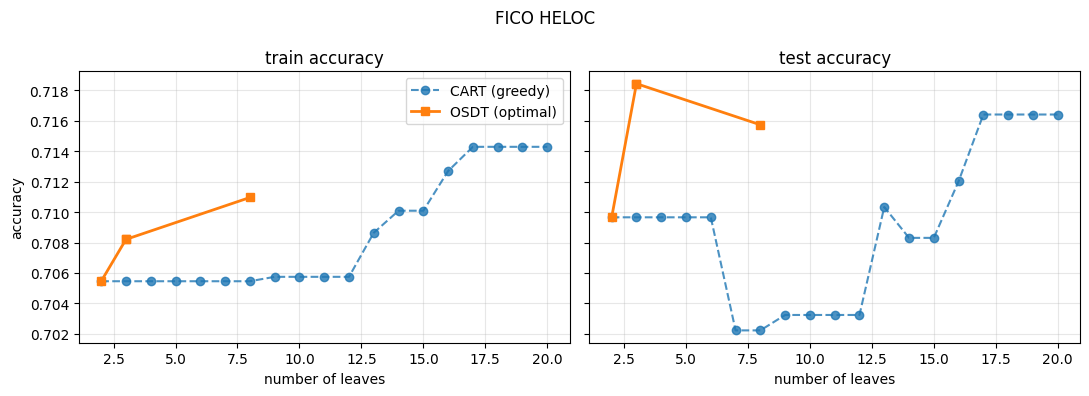

In [8]:
X_fico, y_fico, names_fico = load_fico("heloc_dataset_v1.csv", max_features=10, per_feature=2)
print(X_fico.shape, "default rate:", y_fico.mean().round(3))
print(names_fico)
Xtr_f, Xte_f, ytr_f, yte_f = train_test_split_np(X_fico, y_fico, test_size=0.3, seed=0)

lambs_fico = [0.005, 0.002, 0.001, 0.0005]
res_fico, models_fico = osdt_sweep(Xtr_f, ytr_f, Xte_f, yte_f, lambs_fico, names_fico, time_limit=300) # 35 mins x 4
cart_fico = cart_curve(Xtr_f, ytr_f, Xte_f, yte_f, max_leaves=20)
display(res_fico)
plot_accuracy_vs_leaves(res_fico, cart_fico, "FICO HELOC")

In [9]:
lam_show = min(models_fico, key=lambda l: abs(l - 0.001))
m = models_fico[lam_show]
print(f"lambda={lam_show} -> {m.nleaves_} leaves, train acc {m.train_acc_:.3f}, test acc {m.score(Xte_f, yte_f):.3f}, "
      f"certified optimal: {m.optimal_}\n")
print(m.render())

lambda=0.001 -> 3 leaves, train acc 0.708, test acc 0.718, certified optimal: False

if ExternalRiskEstimate<=72 == 1:
    -> predict 1  [n=3636, correct=2594]
if ExternalRiskEstimate<=72 == 0:
    if NetFractionRevolvingBurden<=56 == 1:
        -> predict 0  [n=3046, correct=2176]
    if NetFractionRevolvingBurden<=56 == 0:
        -> predict 1  [n=227, correct=123]


### 3.1 Convergence with lower-bound scheduling
With `policy="curiosity"` the popped trees' bounds are noisy (they are not popped in bound order).
With `policy="lb"` the lower bound rises **monotonically** until it meets the best objective — the
moment optimality is certified (paper Fig. 2, right panel).

We use $\lambda=0.005$, where the search finishes, so you can *see* the certificate. At $\lambda=0.002$
(10 features) the bound was still ~0.011 below the best objective after 35M trees: the best tree
is probably right, but it is not proven.

policy=lb: leaves=2, R=0.30454, trees=894,027, time=1.9s, certified=True


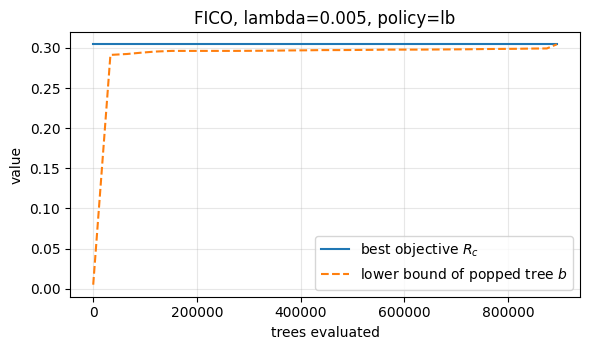

In [10]:
m_lb = OSDT(lamb=0.005, policy="lb", time_limit=180).fit(Xtr_f, ytr_f, names_fico)
print(f"policy=lb: leaves={m_lb.nleaves_}, R={m_lb.objective_:.5f}, trees={m_lb.trees_evaluated:,}, "
      f"time={m_lb.time_:.1f}s, certified={m_lb.optimal_}")
plot_convergence(m_lb, "FICO, lambda=0.005, policy=lb")

## 4. Ablation — how much does each bound help?

We disable **one bound at a time** (as in Table 2 of the supplement) and report the work done.
A time limit keeps slow variants from running forever (a `>` means the run was cut off).

* *FICO*: many loans share all binary features but have different outcomes, so that bound should matter.

In [11]:
def ablation(Xtr, ytr, names, lamb, max_trees=None, time_limit=90):
    variants = {
        "all bounds": {},
        "no lookahead (Lem 3.2)": dict(use_lookahead=False),
        "no equivalent points (Thm B.2)": dict(use_equiv=False),
        "no leaf bounds (Thm 3.3-3.5)": dict(use_leaf_bounds=False),
    }
    rows = []
    for name, kw in variants.items():
        m = OSDT(lamb=lamb, max_trees=max_trees, time_limit=time_limit, **kw).fit(Xtr, ytr, names)
        done = m.optimal_
        rows.append({"variant": name, "finished": done,
                     "trees evaluated": ("" if done else ">") + f"{m.trees_evaluated:,}",
                     "seconds": ("" if done else ">") + f"{m.time_:.1f}",
                     "cached leaves": m.n_cached_leaves_, "objective": round(m.objective_, 5)})
    return pd.DataFrame(rows)


Xtr_t, _, ytr_t, _ = train_test_split_np(X_fico, y_fico, test_size=0.3, seed=0)
print("FICO, lambda=0.05")
display(ablation(Xtr_f, ytr_f, names_fico, lamb=0.05, time_limit=90))

FICO, lambda=0.05


,variant,finished,trees evaluated,seconds,cached leaves,objective
0,all bounds,True,40,0.0,37,0.39454
1,no lookahead (Lem 3.2),True,626,0.0,191,0.39454
2,no equivalent points (Thm B.2),True,"87,703",0.4,2066,0.39454
3,no leaf bounds (Thm 3.3-3.5),True,40,0.0,37,0.39454


## 5. Scheduling policies

If the search runs to completion, every policy evaluates the same trees, so the totals are identical
(and if the best tree is found at the very first step, so is the time-to-best). Order only matters
when the **clock runs out**. So we compare policies on problems that do *not* finish within the
limit, and ask: which policy has found the best tree after the same time budget, and how soon?

In [12]:
print("FICO, lambda=0.002, 60 s each")
display(compare_policies(Xtr_f, ytr_f, names_fico, lamb=0.002, time_limit=60))

FICO, lambda=0.002, 60 s each


,policy,objective,leaves,trees to best,sec to best,total trees,total sec,certified
0,curiosity,0.29779,3,59,0.0,33929625,60.0,False
1,lb,0.29779,3,59,0.0,13196682,66.0,False
2,objective,0.29779,3,83,0.0,21206921,60.0,False
3,bfs,0.29779,3,83,0.0,17617062,60.0,False


## 6. Cross-validation: does optimality on training data help on unseen data?

A single 70/30 split is noisy. Here we use k-fold
cross-validation and compare OSDT with CART **restricted to the same number of leaves**, so any
difference is due to the quality of the tree, not its size. (Runs that hit the time limit are
best-found trees, flagged in `certified`.)

In [13]:
cv_fico, sum_fico = cross_validate(X_fico, y_fico, lamb=0.002, names=names_fico, k=5, time_limit=60)
print("FICO, lambda=0.002, 5-fold"); display(cv_fico.round(4)); display(sum_fico)

FICO, lambda=0.002, 5-fold


,fold,osdt_leaves,osdt_train,osdt_test,cart_leaves,cart_train,cart_test,certified
0,1,3,0.7110,0.7124,3,0.7067,0.7068,False
1,2,3,0.7156,0.6940,3,0.7103,0.6925,False
2,3,3,0.7114,0.7107,3,0.7060,0.7097,False
3,4,3,0.7084,0.7229,3,0.7038,0.7183,False
4,5,3,0.7100,0.7163,3,0.7069,0.7062,False


,osdt_leaves,osdt_train,osdt_test,cart_leaves,cart_train,cart_test
mean,3.0,0.7113,0.7113,3.0,0.7067,0.7067
std,0.0,0.0027,0.0107,0.0,0.0023,0.0093


### 7. Discussion & Findings

*   **Sparsity vs. Accuracy:** The most accurate training tree often overfits test data. OSDT's $\lambda H_d$ penalty enforces Occam's Razor, natively finding the sweet spot for test generalization.
*   **Greedy vs. Optimal:** CART's myopic, top-down splits can permanently trap it in suboptimal topologies. OSDT evaluates globally, consistently finding better trees for the exact same leaf budget.
*   **Stump Optimality:** On FICO, adding a leaf only improves accuracy by $\approx 0.001$. If $\lambda \ge 0.001$, the leaf penalty outweighs the accuracy gain, mathematically guaranteeing a 2-leaf stump is optimal.
*   **Equivalent Points Bound:** Tic-Tac-Toe is deterministic (no conflicting labels for identical states), making the bound $0$. FICO is noisy; tracking minority labels among identical borrowers identifies irreducible error, instantly pruning bad paths.
*   **Scheduling:** *Curiosity* finds the best tree fastest by aggressively diving into high-support leaves. *Lower Bound (`lb`)* is slower but mathematically required to *certify* optimality by monotonically raising the minimum bound floor.
*   **CART Warm-Start:** Initializing the best objective ($R_c$) with a CART tree sets a strict upper ceiling on step one, instantly pruning millions of bad trees that a default $R_c$ would have evaluated.
*   **Scalability:** Increasing features explodes the search space exponentially ($O(3^M)$). *Leaf Support/Accuracy bounds* save the search by dynamically marking features as "dead," pruning vast subtrees early.
*   **Theorem 3.4 (Proof):** Splitting a leaf adds $\lambda$ to the penalty and subtracts $a$ from the error. If gain $a < \lambda$, the total objective strictly worsens ($\Delta R = \lambda - a > 0$). Thus, it cannot be optimal unless refined further.